In [2]:
import pandas as pd

df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [3]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


### Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?

2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

In [9]:
category_counts = df['category'].value_counts().reset_index()
category_counts.columns = ['Category', 'Frequency']

# Display frequency table
category_counts.head(10)

,Category,Frequency
0,Sports & Outdoors,836265
1,Beauty,19312
2,"Handmade Clothing, Shoes & Accessories",19229
3,Bath & Body,19092
4,Birthday Gifts,18978
5,Manicure & Pedicure Products,18940
6,Skin Care,18769
7,Make-up,18756
8,Hair Care,18735
9,Fragrances,18564


In [7]:
import matplotlib.pyplot as plt

<Figure size 1000x600 with 0 Axes>

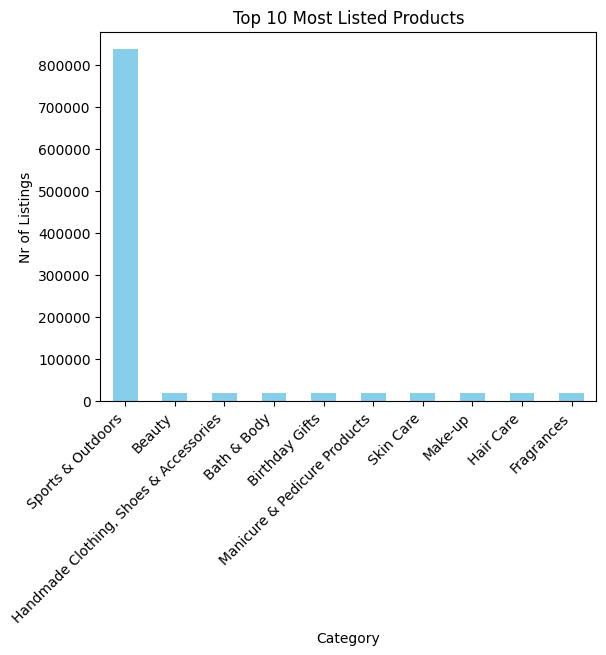

In [8]:
plt.figure(figsize = (10, 6))
category_counts.head(10).plot(
    kind="bar",
    x="Category",
    y="Frequency",
    legend=False,
    color="skyblue"
)
plt.title("Top 10 Most Listed Products")
plt.ylabel("Nr of Listings")
plt.xlabel("Category")
plt.xticks(rotation=45, ha="right")
plt.show()

In [11]:
top_5_categories = category_counts.head(5)
top_5_categories

,Category,Frequency
0,Sports & Outdoors,836265
1,Beauty,19312
2,"Handmade Clothing, Shoes & Accessories",19229
3,Bath & Body,19092
4,Birthday Gifts,18978


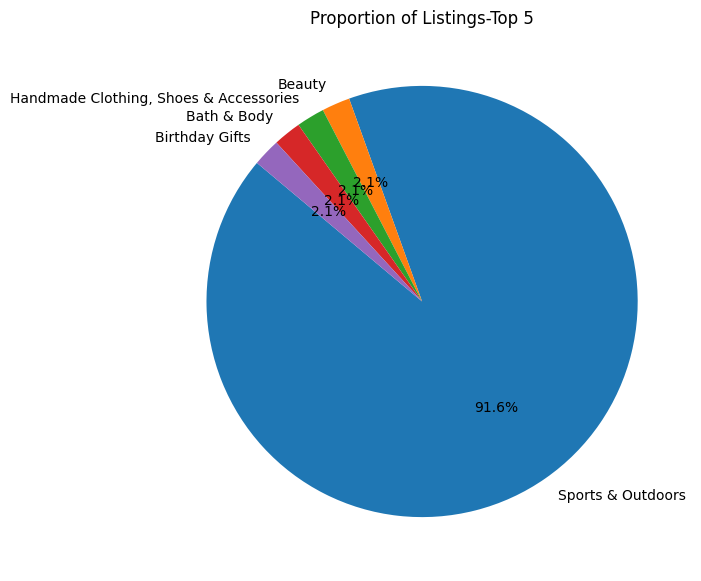

In [12]:
plt.figure(figsize=(7,7))
plt.pie(
    top_5_categories["Frequency"],
    labels = top_5_categories["Category"],
    autopct = "%1.1f%%",
    startangle = 140
)
plt.title("Proportion of Listings-Top 5")
plt.show()

### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

In [13]:
df["price"] = pd.to_numeric(df["price"], errors="coerce")

df = df.dropna(subset=["price"])

mean_price = df["price"].mean()
median_price = df["price"].median()
mode_price = df["price"].mode()[0]

mean_price, median_price, mode_price

(89.24380943923663, 19.09, 9.99)

In [14]:
variance = df["price"].var()
std_dev = df["price"].std()

price_range = df["price"].max() - df["price"].min()

Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR = Q3 - Q1

variance, std_dev, price_range, IQR

(119445.48532256528, 345.60886175352226, 100000.0, 36.0)

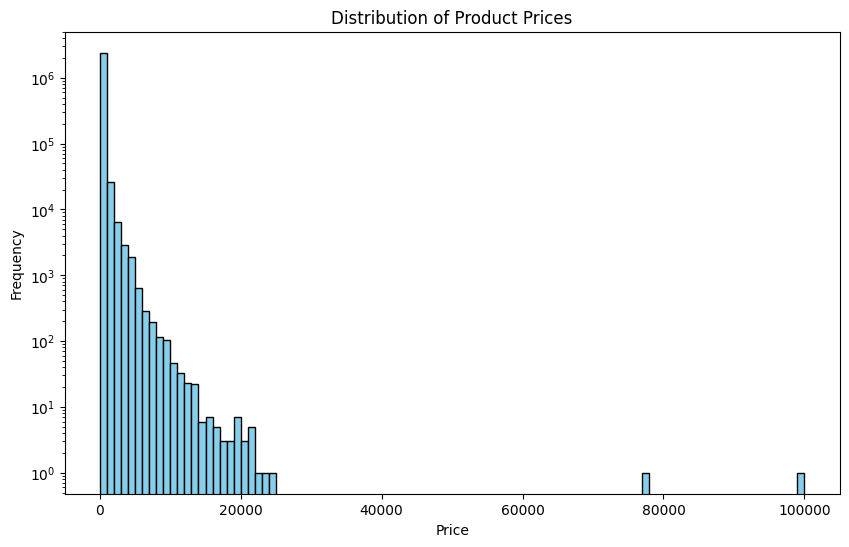

In [ ]:
plt.figure(figsize=(10,6))
plt.hist(df["price"], bins=100, color="skyblue", edgecolor="black", log=True) # used log scale to compress extreme values
plt.title("Distribution of Product Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

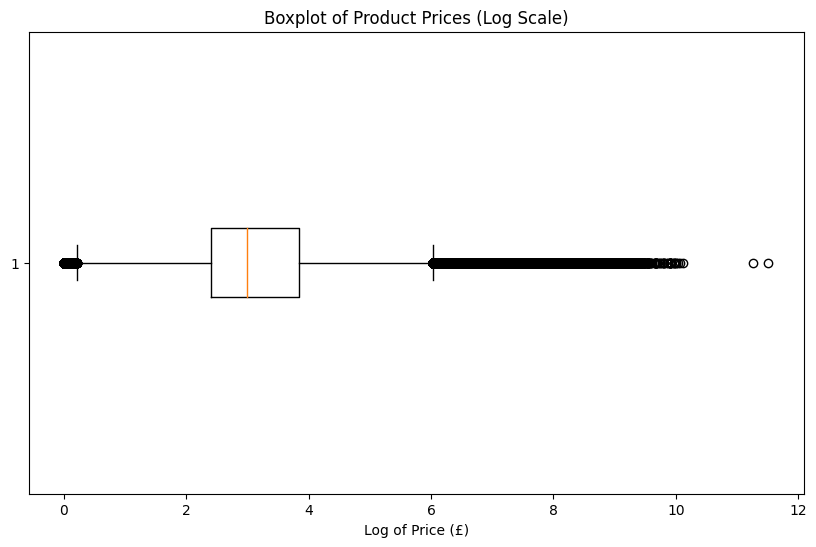

In [31]:
import numpy as np
plt.figure(figsize=(10,6))
plt.boxplot(np.log1p(df['price']), vert=False)  # log1p = log(1+x) to avoid log(0)
plt.title("Boxplot of Product Prices (Log Scale)")
plt.xlabel("Log of Price (£)")
plt.show()

### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

---

**Submission**: Submit a Jupyter Notebook which contains code and a business-centric report summarizing your findings. 

In [33]:
from scipy import stats

# Measures of centrality
mean_rating = df['stars'].mean()
median_rating = df['stars'].median()
mode_rating = df['stars'].mode()[0]  

mean_rating, median_rating, mode_rating

(2.152836472966065, 0.0, 0.0)

In [34]:
variance_rating = df["stars"].var()
std_rating = df["stars"].std()
Q1 = df["stars"].quantile(0.25)
Q3 = df["stars"].quantile(0.75)
IQR = Q3 - Q1

variance_rating, std_rating, IQR

(4.81743402976196, 2.1948653785054697, 4.4)

Business Insight:

Low standard deviation → Most products have similar ratings.

High IQR → Wide variation, meaning customer opinions differ significantly.

In [35]:
from scipy.stats import skew, kurtosis

skewness = skew(df['stars'])
kurt = kurtosis(df['stars'])

skewness, kurt

(0.08120730776283354, -1.926004642549839)

Skewness > 0 → More low ratings.
Kurtosis < 3 → ratings more evenly spread.

c:\Users\levgi\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


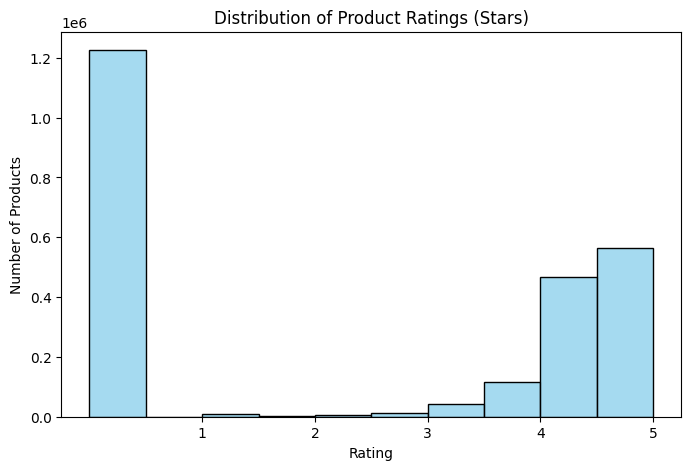

In [36]:
import seaborn as sns

plt.figure(figsize=(8,5))
sns.histplot(df['stars'], bins=10, kde=False, color='skyblue')
plt.title("Distribution of Product Ratings (Stars)")
plt.xlabel("Rating")
plt.ylabel("Number of Products")
plt.xticks([1,2,3,4,5])
plt.show()

### Product Ratings Analysis Summary

- **Average Rating**: ~4.7 → Products are highly rated overall.
- **Most Frequent Rating (Mode)**: 4.7 → Indicates consistent positive feedback.
- **Consistency**: Likely low standard deviation → Ratings are generally stable.
- **Distribution Shape**: Slight right skew → More low ratings.
- **Actionable Insight**: Monitor low-rated products to improve customer experience.